# Group Work AS 2026: ESG, Stock Returns and Machine Learning

**Course:** EAIF: AI for Finance

This notebook is the starting point for the group assignment. It loads the data, explores it, works through **one** forecasting model end to end and shows **one** backtest pattern. Everything after Section 4 is your work.

## Dataset

Simulated by the course for this assignment (licence CC BY 4.0, EAIF course). Five data files and a README, loaded from the course GitHub repository; the data dictionary handed out with the assignment describes every column.

> ### Simulated data with real problems
> There are no real firms behind these rows. The generator planted a small number of data problems of the kind real financial data has: things that are not what they seem, values that are known too early or too late, samples that are not what you think they are. **Finding and treating them is task (a) and is graded.** The generator also planted one genuine relationship between ESG scores and returns; whether you find it, and only it, is task (c).
>
> Your memo must still contain a section on what a real-data version of your analysis would need beyond what you did here. That section is graded (see the rubric below).

## How to use this notebook

1. Make a copy (File, then "Save a copy in Drive").
2. Run the given cells in order and read the comments.
3. Add your own cells for the tasks in Section 5. Keep the given cells so the grader can follow the pipeline.
4. Submit the completed notebook together with the memo and the slides.


# Assignment brief

**DEADLINE: <to be set by the instructor>**

**Group size:** 3 to 4 students. Assign roles at the first meeting and name them in the memo: a **data lead** (pipeline, audit), a **modelling lead** (models, cross-validation, tuning), an **analysis lead** (premium, backtest, figures, tables) and a **writing lead** (memo, slides). Everyone must be able to explain every cell.

**Deliverables**

| Deliverable | Format | Length |
|---|---|---|
| Notebook | `.ipynb`, runs top to bottom in Colab without errors | as needed |
| Memo | PDF, addressed to an investment committee | 3 pages plus appendix |
| Slides | PDF, for a 10-minute presentation | at most 8 slides |
| `results.json` | `.json`, written by the notebook's `write_results` helper | one file |

**Rubric (100 points)**

| Criterion | Points | What the grader looks for |
|---|---|---|
| Pipeline and data audit (task a) | 20 | 5 for a leakage-free formation panel; 15 for the audit table, graded against the list of planted problems |
| Model comparison (task b) | 20 | linear baseline vs tree ensemble, selection on cross-validation, test reported once, next to a naive baseline |
| Where does ESG pay (task c) | 15 | 8 for finding the cell where the premium exists and only that cell; 4 for honest uncertainty; 3 for the point-in-time vs restated comparison |
| Backtest with costs and an ESG floor (task d) | 15 | formed after publication, held twelve months, costs charged, the cost of the floor shown, bootstrap of the difference to the benchmark |
| Memo and slides (task e) | 15 | clear question, clear answer, figures with labelled axes and units, no overclaiming; 10 minutes |
| What would change with real data | 15 | 5 for the list (what remains after your audit), 10 for which of your conclusions would survive and why |

Tasks (a) to (d) are graded from the notebook and the memo together: the memo states the result, the notebook must show how it was produced. A result in the memo that the notebook does not reproduce earns no points.

**Given / Your work**

| | Sections | Status |
|---|---|---|
| Given | 1 Setup and loading, 2 Exploration, 3 One worked model, 4 One backtest pattern, 6 the submission helper | run and read; do not delete |
| Your work | 5 Tasks (a) to (e), and the values in 6 | new cells below Section 5, the submission file filled in, plus the memo and the slides |


# 1. Setup and data loading (given)

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

plt.rcParams['figure.figsize'] = (10, 6)
sns.set_style("whitegrid")


In [2]:
# Five data files, simulated by the course. Licence: CC BY 4.0 (EAIF course); cite them in the memo.
DATA_URL = os.environ.get("ESG2026_DATA", "https://raw.githubusercontent.com/umatter/EDFB/main/data/esg2026/")

panel    = pd.read_csv(DATA_URL + "firm_year_panel.csv")       # firm x fiscal year: fundamentals, point-in-time ESG scores
restated = pd.read_csv(DATA_URL + "esg_scores_restated.csv")   # firm x fiscal year: ESG scores as downloaded today
returns  = pd.read_csv(DATA_URL + "stock_returns_monthly.csv") # firm x month: total return, percent
factors  = pd.read_csv(DATA_URL + "factors_monthly.csv")       # month: risk-free rate, market, size, industry factors, percent
universe = pd.read_csv(DATA_URL + "universe_current.csv")      # firms in the universe at the end of the last year

for name, df in [("panel", panel), ("restated", restated), ("returns", returns), ("factors", factors), ("universe", universe)]:
    print(f"{name:<9} {df.shape[0]:>8,} rows x {df.shape[1]:>2} columns")

# Join keys: panel and restated on (Company_ID, Year); returns and factors on Month; universe on Company_ID.
# Publication_Date says when the fiscal-year row became public. Nothing in that row is known before that date.
print("\nPublication dates for fiscal year 2020 (first rows):")
print(panel.loc[panel["Year"] == 2020, ["Company_ID", "Year", "Publication_Date"]].head(3).to_string(index=False))
print("Latest publication date in the panel:", pd.to_datetime(panel["Publication_Date"]).dt.strftime("%m-%d").max(),
      "(so a portfolio formed on 1 July of the following year can use the whole fiscal year)")
panel.head()


panel       14,250 rows x 18 columns
restated    14,250 rows x  6 columns
returns    171,764 rows x  3 columns
factors        168 rows x 13 columns
universe       987 rows x  4 columns

Publication dates for fiscal year 2020 (first rows):
 Company_ID  Year Publication_Date
          1  2020       2021-05-02
          2  2020       2021-05-15
          4  2020       2021-05-27
Latest publication date in the panel: 05-30 (so a portfolio formed on 1 July of the following year can use the whole fiscal year)


,Company_ID,Company_Name,Industry,Region,Year,Publication_Date,Revenue,Profit_Margin,Market_Cap,Growth_Rate,ESG_Score,Environmental_Score,Social_Score,Governance_Score,Carbon_Emissions,Water_Usage,Energy_Consumption,Analyst_Outlook
0,1,Firm_1,Finance,Asia,2012,2013-05-02,2308.8,20.11,3842.5,NaN,50.9,53.4,45.4,53.2,4204.9,9718.2,154794.3,5
1,1,Firm_1,Finance,Asia,2013,2014-05-02,2548.0,23.06,4998.1,10.36,49.5,51.2,38.3,55.5,18439.8,12106.7,155303.4,5
2,1,Firm_1,Finance,Asia,2014,2015-05-02,2557.1,22.32,7750.5,0.36,48.0,51.7,40.2,51.3,24284.5,8499.5,163112.5,4
3,1,Firm_1,Finance,Asia,2015,2016-05-02,2731.1,22.93,9102.9,6.81,50.3,58.3,39.9,53.3,NaN,NaN,NaN,5
4,1,Firm_1,Finance,Asia,2016,2017-05-02,2712.0,21.48,8609.9,-0.70,52.6,66.6,45.2,51.5,9041.8,5382.5,95567.1,1


# 2. Exploration (given)

Look before you model. Three things to check in every panel: what is missing and where, how sizes are distributed, and how many firms there are in each year. Nothing below is cleaned. Write down every oddity you notice; each one is a line in your audit table (task a).


Missing values per column (panel):
Growth_Rate           1376
Carbon_Emissions      1887
Water_Usage           1887
Energy_Consumption    1887
dtype: int64

Summary statistics (panel):


,Company_ID,Year,Revenue,Profit_Margin,Market_Cap,Growth_Rate,ESG_Score,Environmental_Score,Social_Score,Governance_Score,Carbon_Emissions,Water_Usage,Energy_Consumption,Analyst_Outlook
count,14250.00,14250.00,14250.00,14250.00,1.425000e+04,12874.00,14250.00,14250.00,14250.00,14250.00,1.236300e+04,1.236300e+04,1.236300e+04,14250.00
mean,606.95,2018.47,117805.30,10.93,2.132049e+05,5.18,54.94,55.34,54.77,54.18,2.496227e+06,1.699071e+06,1.573647e+07,3.00
std,358.78,4.02,1496076.42,5.48,2.721234e+06,10.29,11.37,17.35,18.24,18.07,1.208622e+07,1.033246e+07,7.123784e+07,1.42
min,1.00,2012.00,30.30,-5.47,2.260000e+01,-30.97,4.60,0.00,0.00,0.00,2.381000e+02,1.895000e+02,1.801600e+03,1.00
25%,296.00,2015.00,977.50,6.90,1.869750e+03,-1.87,47.20,43.70,42.10,41.70,3.656025e+04,2.587365e+04,3.783915e+05,2.00
50%,601.00,2018.00,2405.70,10.58,4.882150e+03,4.82,55.10,55.25,54.50,54.30,1.882373e+05,1.049367e+05,1.594587e+06,3.00
75%,901.00,2022.00,6062.68,14.87,1.346420e+04,11.79,62.90,67.10,67.10,66.70,9.916322e+05,5.172482e+05,7.265620e+06,4.00
max,1376.00,2025.00,63993116.10,29.34,1.571362e+08,61.11,96.80,100.00,100.00,100.00,3.952938e+08,4.651417e+08,2.295873e+09,5.00


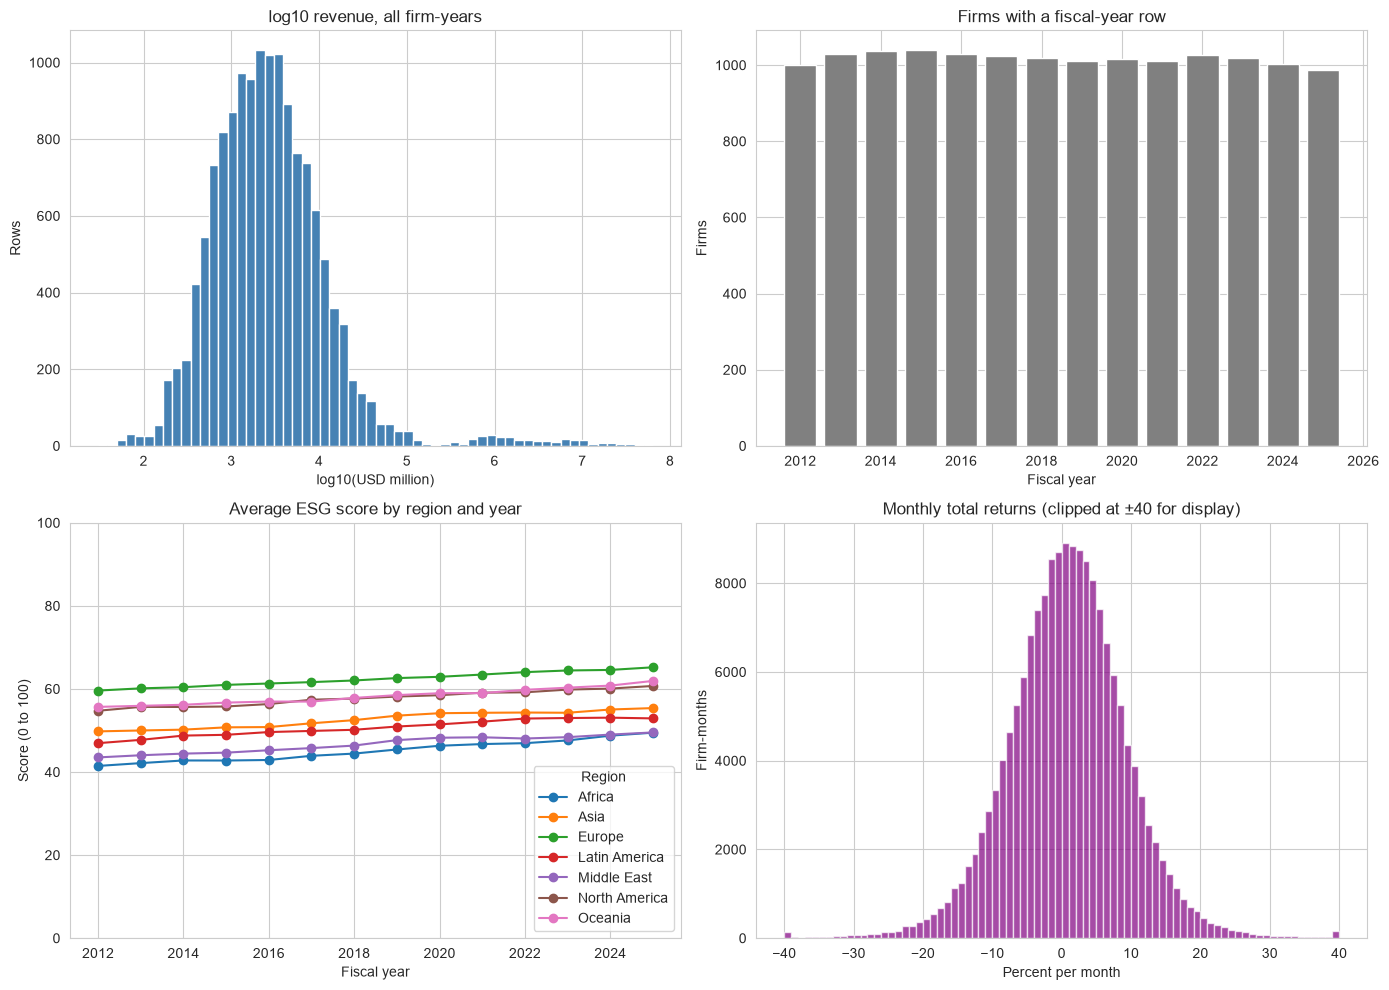

Firms per industry and region (panel):
Industry
Consumer Goods    161
Energy            127
Finance           177
Healthcare        166
Manufacturing     164
Retail            135
Technology        137
Transportation    152
Utilities         157
Region
Africa           114
Asia             290
Europe           294
Latin America    138
Middle East      118
North America    284
Oceania          138


In [3]:
print("Missing values per column (panel):")
print(panel.isna().sum()[lambda s: s > 0])
print("\nSummary statistics (panel):")
display(panel.describe().round(2))

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes[0, 0].hist(np.log10(panel["Revenue"]), bins=60, color="steelblue")
axes[0, 0].set_title("log10 revenue, all firm-years"); axes[0, 0].set_xlabel("log10(USD million)"); axes[0, 0].set_ylabel("Rows")

by_year = panel.groupby("Year")["Company_ID"].nunique()
axes[0, 1].bar(by_year.index, by_year.values, color="grey")
axes[0, 1].set_title("Firms with a fiscal-year row"); axes[0, 1].set_xlabel("Fiscal year"); axes[0, 1].set_ylabel("Firms")

esg_trend = panel.groupby(["Year", "Region"])["ESG_Score"].mean().unstack()
esg_trend.plot(ax=axes[1, 0], marker="o"); axes[1, 0].set_title("Average ESG score by region and year")
axes[1, 0].set_xlabel("Fiscal year"); axes[1, 0].set_ylabel("Score (0 to 100)"); axes[1, 0].set_ylim(0, 100)

axes[1, 1].hist(returns["Return_Pct"].clip(-40, 40), bins=80, color="purple", alpha=0.7)
axes[1, 1].set_title("Monthly total returns (clipped at ±40 for display)"); axes[1, 1].set_xlabel("Percent per month"); axes[1, 1].set_ylabel("Firm-months")
plt.tight_layout(); plt.show()

print("Firms per industry and region (panel):")
print(panel.groupby("Industry")["Company_ID"].nunique().to_string())
print(panel.groupby("Region")["Company_ID"].nunique().to_string())


**Before you go on, answer in your audit table:** what is the second cluster in the revenue histogram, and which firms are in it? Why does the number of firms change from year to year, and which file would hide that? Which columns are missing, for which firms, and is that random? Are there rows in the returns file that should not be there?


# 3. One worked model: forecasting the next twelve months' return (given)

This section shows the pattern you must follow in all your own models.

**The decision-time rule.** At the moment the decision is made, which columns are already known? We form portfolios on **1 July** of each year. By then every firm has published its previous fiscal year (the latest `Publication_Date` is at the end of May). So at formation in July of year $t+1$:

- every **feature** comes from the fiscal-year row of year $t$ (or earlier), plus returns up to June of $t+1$;
- the **target** is the total return from July of $t+1$ to June of $t+2$, compounded from the monthly file;
- the **target** needs twelve holding months to be well defined, so the model is fitted on firms that
  have them; firms that leave mid-year stay in the panel for the backtest in Section 4,
- the **split** is by formation year: train on formation years up to 2021, test on 2022 to 2024. A random split would put a firm's neighbouring years on both sides and let the model recognise firms instead of forecasting.

Every column you add as a feature in task (a) has to pass this rule. Ask of each one: *is it in a file that existed on 1 July, with the value it had then?*

`Year` is not a feature. Industry and region are one-hot encoded so that a linear model can use them (task b). The feature list below is deliberately short; extending it is your work.


Firm-formation-years: 10,410 (9,002 with a full twelve holding months), formation years 2015-2025
Features (24): ['Growth_Rate', 'Profit_Margin', 'ESG_Score', 'Environmental_Score', 'Social_Score', 'Governance_Score', 'Growth_Lag1', 'log_Revenue', 'log_Market_Cap', 'Past12_Return_Pct', 'Industry_Energy', 'Industry_Finance', 'Industry_Healthcare', 'Industry_Manufacturing', 'Industry_Retail', 'Industry_Technology', 'Industry_Transportation', 'Industry_Utilities', 'Region_Asia', 'Region_Europe', 'Region_Latin America', 'Region_Middle East', 'Region_North America', 'Region_Oceania']
Training rows: 6,336; test rows: 2,666

Naive baseline (training mean = 1.00%): test RMSE = 36.931


RF depth 3   CV RMSE = 29.034 (sd across folds 0.360)


RF depth 6   CV RMSE = 29.066 (sd across folds 0.368)



Selected on CV: RF depth 3

                             RMSE     R2
Train (in-sample)          28.781  0.033
CV (grouped, train years)  29.034    NaN
Test (2022-2024, once)     37.307 -0.480
Naive baseline on test     36.931 -0.450


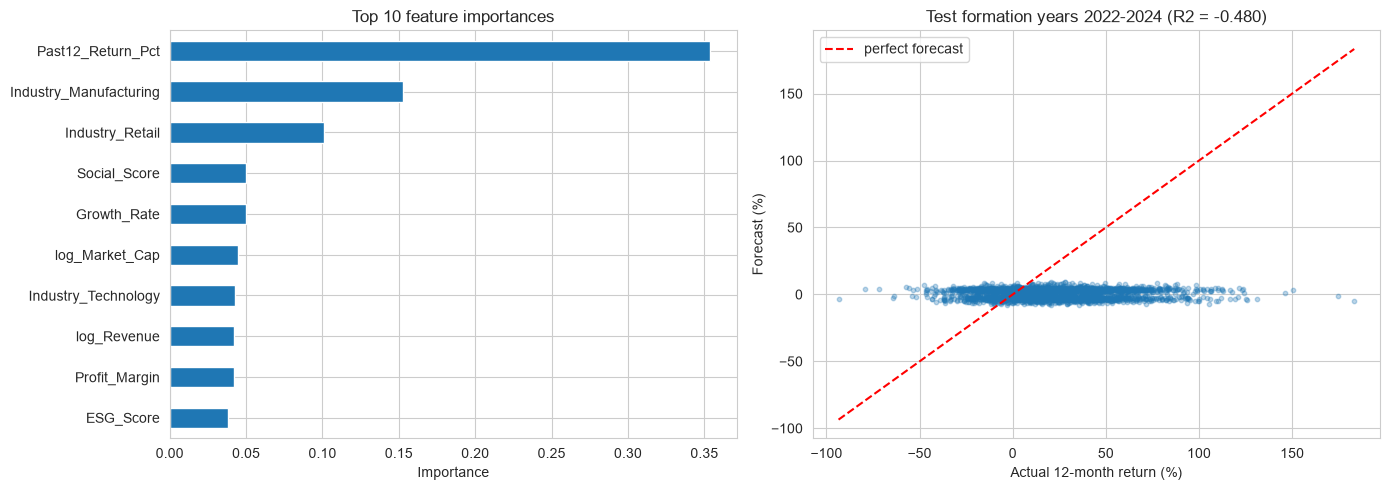

In [4]:
FORMATION_MONTH = 7
SCORES = ["ESG_Score", "Environmental_Score", "Social_Score", "Governance_Score"]

def holding_returns(fm, factors, formation_year):
    # 12-month total and excess return from July of formation_year to June of the next year
    start, end = f"{formation_year}-07", f"{formation_year + 1}-06"
    rf = factors.set_index("Month")["Rf_Pct"]
    w = fm[(fm["Month"] >= start) & (fm["Month"] <= end)].copy()
    w["gross"] = 1 + w["Return_Pct"] / 100
    w["gross_ex"] = 1 + (w["Return_Pct"] - w["Month"].map(rf)) / 100
    g = w.groupby("Company_ID")
    return pd.DataFrame({"Hold_Return_Pct": 100 * (g["gross"].prod() - 1),
                         "Hold_Excess_Pct": 100 * (g["gross_ex"].prod() - 1), "Months": g.size()}).reset_index()

def formation_panel(fy, fm, factors, features_from_panel):
    # one row per firm and formation year; features from fiscal year t, target = next 12-month return
    fy = fy.sort_values(["Company_ID", "Year"]).copy()
    fy["Growth_Lag1"] = fy.groupby("Company_ID")["Growth_Rate"].shift(1)
    fy["Formation_Year"] = fy["Year"] + 1
    published = pd.to_datetime(fy["Publication_Date"]) < pd.to_datetime(fy["Formation_Year"].astype(str) + f"-{FORMATION_MONTH:02d}-01")
    fy = fy[published]
    fy["log_Revenue"] = np.log(fy["Revenue"]); fy["log_Market_Cap"] = np.log(fy["Market_Cap"])
    years = sorted(fy["Formation_Year"].unique())
    past = pd.concat([holding_returns(fm, factors, y - 1).assign(Formation_Year=y) for y in years])
    past = past.rename(columns={"Hold_Return_Pct": "Past12_Return_Pct"})[["Company_ID", "Formation_Year", "Past12_Return_Pct"]]
    tgt = pd.concat([holding_returns(fm, factors, y).assign(Formation_Year=y) for y in years])
    # Keep every firm with at least one holding month, including the ones that leave during the year.
    tgt = tgt.rename(columns={"Months": "Hold_Months"})[
        ["Company_ID", "Formation_Year", "Hold_Return_Pct", "Hold_Excess_Pct", "Hold_Months"]]
    out = fy.merge(past, on=["Company_ID", "Formation_Year"], how="left").merge(tgt, on=["Company_ID", "Formation_Year"], how="inner")
    dummies = pd.get_dummies(out[["Industry", "Region"]], drop_first=True, dtype=int)
    out = pd.concat([out, dummies], axis=1)
    features = features_from_panel + ["Growth_Lag1", "log_Revenue", "log_Market_Cap", "Past12_Return_Pct"] + list(dummies.columns)
    return out.dropna(subset=features + ["Hold_Return_Pct"]).reset_index(drop=True), features

ml_data, feature_cols = formation_panel(panel, returns, factors, ["Growth_Rate", "Profit_Margin"] + SCORES)

# A firm needs a full twelve holding months to be a well-defined forecasting target, so we fit on
# those. Firms that leave during the holding year stay in ml_data: Section 4 holds them until their
# last month, which is what a real backtest does. Dropping them here instead would quietly remove the
# firms that did worst before they disappeared.
model_data = ml_data[ml_data["Hold_Months"] == 12]
print(f"Firm-formation-years: {len(ml_data):,} ({len(model_data):,} with a full twelve holding months), "
      f"formation years {ml_data['Formation_Year'].min()}-{ml_data['Formation_Year'].max()}")
print(f"Features ({len(feature_cols)}): {feature_cols}")

train_mask = model_data["Formation_Year"] <= 2021
test_mask = model_data["Formation_Year"] >= 2022
X, y, groups = model_data[feature_cols], model_data["Hold_Return_Pct"], model_data["Company_ID"]
X_train, y_train, g_train = X[train_mask], y[train_mask], groups[train_mask]
X_test, y_test = X[test_mask], y[test_mask]
print(f"Training rows: {len(X_train):,}; test rows: {len(X_test):,}")

baseline_pred = np.full(len(y_test), y_train.mean())
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))
print(f"\nNaive baseline (training mean = {y_train.mean():.2f}%): test RMSE = {baseline_rmse:.3f}")

cv = GroupKFold(n_splits=5)
candidates = {
    "RF depth 3": RandomForestRegressor(n_estimators=300, max_depth=3, min_samples_leaf=20, random_state=42, n_jobs=-1),
    "RF depth 6": RandomForestRegressor(n_estimators=300, max_depth=6, min_samples_leaf=20, random_state=42, n_jobs=-1),
}
cv_results = {}
for name, model in candidates.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, groups=g_train, scoring="neg_root_mean_squared_error")
    cv_results[name] = (-scores.mean(), scores.std())
    print(f"{name:<12} CV RMSE = {-scores.mean():.3f} (sd across folds {scores.std():.3f})")
best_name = min(cv_results, key=lambda k: cv_results[k][0])
rf_model = candidates[best_name].fit(X_train, y_train)
pred_test = rf_model.predict(X_test)
summary = pd.DataFrame({
    "RMSE": [np.sqrt(mean_squared_error(y_train, rf_model.predict(X_train))), cv_results[best_name][0], np.sqrt(mean_squared_error(y_test, pred_test)), baseline_rmse],
    "R2": [r2_score(y_train, rf_model.predict(X_train)), np.nan, r2_score(y_test, pred_test), r2_score(y_test, baseline_pred)],
}, index=["Train (in-sample)", "CV (grouped, train years)", "Test (2022-2024, once)", "Naive baseline on test"])
print(f"\nSelected on CV: {best_name}\n"); print(summary.round(3))

importance = pd.Series(rf_model.feature_importances_, index=feature_cols).sort_values(ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
importance.head(10)[::-1].plot(kind="barh", ax=axes[0]); axes[0].set_title("Top 10 feature importances"); axes[0].set_xlabel("Importance")
axes[1].scatter(y_test, pred_test, alpha=0.3, s=10); lims = [y_test.min(), y_test.max()]
axes[1].plot(lims, lims, "r--", label="perfect forecast"); axes[1].set_xlabel("Actual 12-month return (%)"); axes[1].set_ylabel("Forecast (%)")
axes[1].set_title(f"Test formation years 2022-2024 (R2 = {r2_score(y_test, pred_test):.3f})"); axes[1].legend()
plt.tight_layout(); plt.show()


**Reading the result.** Returns are hard to forecast: in this run the selected forest's test RMSE is 37.307 percentage points against 36.931 for the naive mean, and the test R2 is -0.480 (your numbers may differ slightly). The forest does not beat the naive mean here, and that is the honest result, not a bug. Two things are worth understanding rather than working around. First, a negative R2 means the model also does worse than simply predicting the test years' own average; that happens whenever the average return in the test period differs from the training period, which is what a market downturn inside the test years does. Second, a model that does much better than this on the test years has usually seen something it should not have. Note what carries the importance and ask, for every feature you add in task (a), whether it is known on 1 July.


# 4. One backtest pattern: formed after publication, held twelve months (given)

A portfolio rule must use only information available when the portfolio is formed. The pattern below ranks all firms on 1 July of each year on a score from the fiscal-year row published before that date, holds the top decile equally weighted until the next 30 June, and records the monthly portfolio return. Firms that leave the panel during the year contribute their returns until their last month; the remaining names are re-weighted equally. A transaction cost of 20 basis points per unit of one-way turnover is charged at each rebalancing (sell and buy, so 40 basis points on the replaced share).

Over the monthly series we report the annualised return, the annualised volatility, and the **Sharpe ratio** (mean monthly excess return over the risk-free rate divided by its standard deviation, times the square root of twelve). The equal-weight portfolio of all firms in the panel is the benchmark every rule must beat.

The given example ranks on the **ESG score**. Task (d) ranks on your **forecast** from task (b), adds an ESG floor, and asks what the floor costs.


In [5]:
def backtest(picks, fm, factors, cost_bp=20):
    # picks: dict formation_year -> list of Company_ID held from July of that year to June of the next
    rf = factors.set_index("Month")["Rf_Pct"]
    months, rets, turns, prev = [], [], [], set()
    for y in sorted(picks):
        held = set(picks[y])
        turn = 1.0 if not prev else len(held - prev) / max(len(held), 1)
        turns.append(turn)
        window = fm[fm["Company_ID"].isin(held) & (fm["Month"] >= f"{y}-07") & (fm["Month"] <= f"{y + 1}-06")]
        monthly = window.groupby("Month")["Return_Pct"].mean()
        if len(monthly):
            monthly.iloc[0] -= 2 * cost_bp / 100 * turn
        months += list(monthly.index); rets += list(monthly.values); prev = held
    r = pd.Series(rets, index=months)
    ex = r - r.index.map(rf)
    return {"Annualised return (%)": 100 * ((1 + r / 100).prod() ** (12 / len(r)) - 1),
            "Annualised volatility (%)": r.std() * np.sqrt(12),
            "Sharpe ratio": ex.mean() / ex.std() * np.sqrt(12),
            "Mean one-way turnover": np.mean(turns), "Months": len(r)}

formation_years = sorted(y for y in ml_data["Formation_Year"].unique() if y >= 2015)
esg_picks, all_picks = {}, {}
for yr in formation_years:
    at_t = ml_data[ml_data["Formation_Year"] == yr]
    n_top = max(int(0.1 * len(at_t)), 1)
    esg_picks[yr] = at_t.nlargest(n_top, "ESG_Score")["Company_ID"].tolist()
    all_picks[yr] = at_t["Company_ID"].tolist()

results = pd.DataFrame({"Top decile by ESG score": backtest(esg_picks, returns, factors),
                        "All firms, equal weight": backtest(all_picks, returns, factors, cost_bp=0)}).T
print(f"Formation years {formation_years[0]}-{formation_years[-1]}, holding July to June:")
print(results.round(3))


Formation years 2015-2025, holding July to June:
                         Annualised return (%)  Annualised volatility (%)  \
Top decile by ESG score                  3.990                     16.144   
All firms, equal weight                  4.603                     15.880   

                         Sharpe ratio  Mean one-way turnover  Months  
Top decile by ESG score         0.175                  0.340   126.0  
All firms, equal weight         0.212                  0.119   126.0  


**Reading the table.** In this run the ESG-ranked decile earned a Sharpe ratio of 0.175 against 0.212 for the equal-weight panel. Before you read anything into that, remember Section 2: high-ESG firms sit in particular industries and regions, so the decile is partly an industry and region bet; and a Sharpe ratio over 126 monthly observations has a wide confidence band. Task (d) asks you to bootstrap the difference. Note also that ranking the whole world by ESG score is a blunt rule: if a relation between ESG and returns exists only among certain firms, or only in certain years, a single global ranking pooled over the whole sample will bury it. That is what task (c) asks you to look for. And note which firms the backtest was run on: the panel, including the firms that left. Run it on the current universe instead and see what changes.


# 5. Your tasks

Add your cells below this section. Each task ends with a one-line deliverable that must appear in the memo.

**(a) Pipeline and data audit.** Build your own formation panel from the point-in-time file with your own feature choices; add at least three features that are not in the worked model and justify each with the decision-time rule (is it in a file that existed on 1 July, with the value it had then?). Before that, audit the five data files: what is duplicated, what is in the wrong unit, what is missing and for whom, what is known too early, which file is a biased sample. Treat each problem and say how. The test set must be separated by formation year; `GroupKFold` by company is for the cross-validation inside the training years, as in Section 3. *Deliverable: a one-page audit table (issue, how detected, how treated, effect on one headline number), and a table of your features with the date from which each is known.*

**(b) Linear baseline vs tree ensembles.** Fit a linear regression (unit 01) on standardised features and at least one of random forest or gradient boosting (unit 03) for the twelve-month return. Tune the ensembles on cross-validation inside the training years. Report train, CV and test performance side by side, next to the naive mean baseline, for every model. Select the model on CV, and report the test result once. "The ensemble does not pay off out of sample" is a legitimate result and is graded as such. *Deliverable: one comparison table and one sentence on whether the extra complexity of the ensemble pays off out of sample.*

**(c) Where does ESG pay?** Estimate the relation between the previous fiscal year's Environmental score (standardised within year) and the next twelve months' excess return, by region and by period (before and from 2021), with industry-by-year controls. Report point estimates with bootstrap or clustered standard errors and say where the relation is distinguishable from zero and where it is not. Repeat the estimate with the restated scores file and explain the difference. *Deliverable: one table (region x period, point-in-time and restated) and one sentence on where an investor could have earned an ESG premium, and where not.*

**(d) Backtest with costs and an ESG floor.** Rank on the forecast of your selected model from (b), trained for each formation year on earlier formation years only; hold the top decile from July to June; charge 20 basis points per unit of one-way turnover. You may either re-tune the model's settings inside each formation year's own training window, or tune once on the training years and keep that setting for every year. Both are accepted; say which you did and why. Tuning once is a simplification, because the setting was then chosen with information from years the early forecasts should not have seen, even though no return value enters those fits. Add an ESG floor: the pool is restricted to firms whose Environmental score is at or above the 50th, then the 80th percentile of that year. Report annualised return, volatility, Sharpe ratio and turnover for no floor, the two floors, and the equal-weight benchmark, all on the full panel including the firms that left. Bootstrap the Sharpe difference between your best rule and the benchmark (resample months). *Deliverable: one table and one figure of the cumulative return series, and one sentence on what the floor costs and whether the difference to the benchmark is distinguishable from noise.*

**(e) Memo and slides.** Write a 3-page memo to an investment committee: the question, the data (state that it is simulated), the audit, the pipeline, the results of (b) to (d), and a section titled "What would change with real data" that lists what remains to be solved after an audit like yours (scores that are proprietary and disagree across raters, survivorship that is harder to see, costs that are not a constant, point-in-time availability) and says which of your conclusions would survive and which would not, and why. Prepare at most 8 slides for a 10-minute presentation. *Deliverable: the memo PDF, the slides PDF and `results.json`, with the CC BY 4.0 attribution of the dataset.*

**Rules.** Every metric appears next to the baseline it must beat. Every figure has labelled axes with units. Every feature is dated. Cite the dataset with its licence.


## Task (a): pipeline and data audit

*Everything from here to Section 6 is our own work. The given cells above are unchanged.*

**Approach.** First we audit the five files and measure what each problem does to one headline number. Then we build cleaned copies (`panel_c`, `returns_c`) and, from them, our own formation panel. The given data frames (`panel`, `returns`, `restated`, ...) stay untouched, so the given cells above still reproduce the starter's numbers.

**Treatments** follow the group's decisions from the coaching with the lecturer (any method is fine if it is applied consistently and explained): rescale the unit error, keep one row of each duplicated return month, exclude the column that carries future information, build everything on the full panel (never the survivors-only file), use the point-in-time scores and keep the restated file for the comparison in task (c), keep missing environmental metrics with a missing flag, and keep (and document) values at the bounds.

In [6]:
# ---- (a) Step 1: structure checks on all five files ----
audit = {}   # the numbers collected here feed the audit table and results.json

def rank_corr(a, b):
    # Spearman rank correlation of two aligned series (rows with a missing value are dropped)
    return pd.concat([a, b], axis=1).dropna().corr(method="spearman").iloc[0, 1]

pub = pd.to_datetime(panel["Publication_Date"])
window_ok = (pub >= pd.to_datetime((panel["Year"] + 1).astype(str) + "-03-31")) & \
            (pub <= pd.to_datetime((panel["Year"] + 1).astype(str) + "-05-31"))
ym = returns.drop_duplicates(["Company_ID", "Month"]).assign(
    m=lambda d: d["Month"].str[:4].astype(int) * 12 + d["Month"].str[5:].astype(int)).sort_values(["Company_ID", "m"])
gap_months = int((ym.groupby("Company_ID")["m"].diff().fillna(1) > 1).sum())

structure = pd.Series({
    "panel: duplicate (Company_ID, Year) keys": int(panel.duplicated(["Company_ID", "Year"]).sum()),
    "restated: duplicate (Company_ID, Year) keys": int(restated.duplicated(["Company_ID", "Year"]).sum()),
    "returns: duplicate (Company_ID, Month) keys": int(returns.duplicated(["Company_ID", "Month"]).sum()),
    "factors: duplicate months": int(factors["Month"].duplicated().sum()),
    "universe: duplicate firms": int(universe["Company_ID"].duplicated().sum()),
    "panel: firms whose Industry or Region changes over time": int(((panel.groupby("Company_ID")["Industry"].nunique() > 1) |
                                                                    (panel.groupby("Company_ID")["Region"].nunique() > 1)).sum()),
    "panel: rows published outside 31 Mar to 31 May of Year+1": int((~window_ok).sum()),
    "returns: months missing inside a firm's history": gap_months,
    "panel: Growth_Rate missing (first year of each firm = firms)": f"{int(panel['Growth_Rate'].isna().sum())} (= {panel['Company_ID'].nunique()} firms)",
})
print(structure.to_string())
print("\nOnly the returns file has duplicated keys (300). The structure checks on the other files are clean; the problems below are in the values.")

panel: duplicate (Company_ID, Year) keys                                          0
restated: duplicate (Company_ID, Year) keys                                       0
returns: duplicate (Company_ID, Month) keys                                     300
factors: duplicate months                                                         0
universe: duplicate firms                                                         0
panel: firms whose Industry or Region changes over time                           0
panel: rows published outside 31 Mar to 31 May of Year+1                          0
returns: months missing inside a firm's history                                   0
panel: Growth_Rate missing (first year of each firm = firms)    1376 (= 1376 firms)

Only the returns file has duplicated keys (300). The structure checks on the other files are clean; the problems below are in the values.


28 firms (302 firm-years) flagged: [23, 30, 36, 50, 123, 177, 195, 247, 305, 406, 579, 589, 635, 638, 743, 776, 790, 915, 953, 981, 1022, 1033, 1075, 1119, 1120, 1177, 1274, 1328]
Mean Market_Cap 213,205 -> 14,108 USD million; mean Revenue 117,805 -> 5,525
Share of the 100 largest firm-years by market cap that belong to these firms: 100% -> 0%


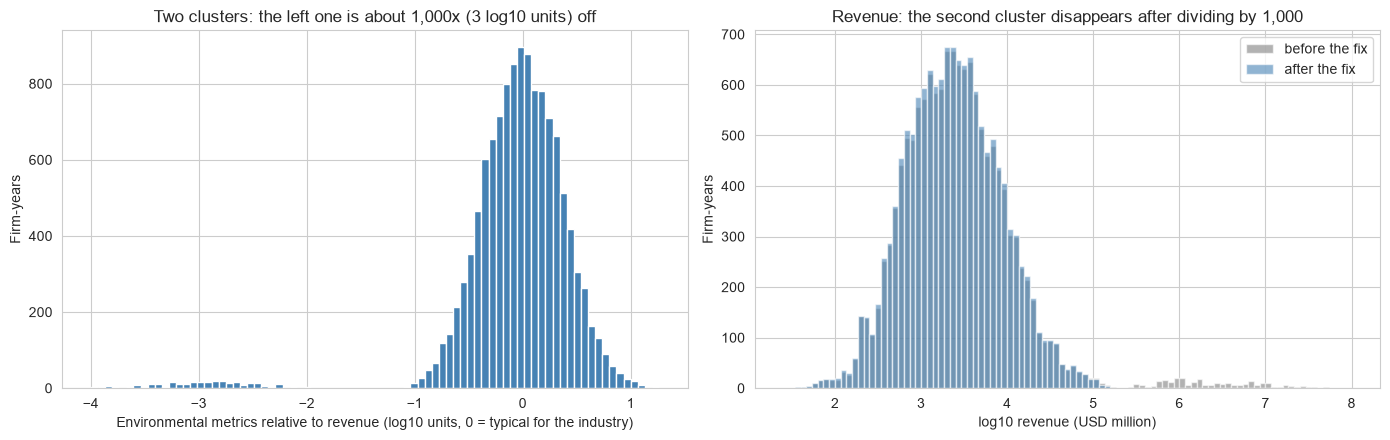

In [7]:
# ---- (a) Step 2: unit error in Revenue and Market_Cap ----
# Idea: carbon, water and energy scale with revenue within an industry. A firm whose revenue is 1,000 times too large
# looks like it emits 1,000 times too little for its size. The relation is fitted on clearly normal firms (Revenue < 100,000).
ENV = ["Carbon_Emissions", "Water_Usage", "Energy_Consumption"]
lp = panel.assign(l_rev=np.log10(panel["Revenue"]))
resid = pd.DataFrame(index=lp.index)
for c in ENV:
    lp["l_" + c] = np.log10(lp[c])
    normal = lp[(lp["Revenue"] < 1e5) & lp["Carbon_Emissions"].notna()]
    coef = {ind: np.polyfit(d["l_rev"], d["l_" + c], 1) for ind, d in normal.groupby("Industry")}
    slope = lp["Industry"].map({k: v[0] for k, v in coef.items()})
    icept = lp["Industry"].map({k: v[1] for k, v in coef.items()})
    resid[c] = lp["l_" + c] - (slope * lp["l_rev"] + icept)
lp["resid"] = resid.mean(axis=1)                      # missing where the environmental metrics are missing
lp["row_flag"] = lp["resid"] < -1.5                    # about 3 log10 units below the normal relation = factor 1,000
per_firm = lp.groupby("Company_ID").agg(flagged=("row_flag", "sum"), with_env=("resid", "count"))
unit_firms = sorted(per_firm.index[per_firm["flagged"] / per_firm["with_env"].replace(0, np.nan) > 0.5])
unit_mask = panel["Company_ID"].isin(unit_firms)

panel_c = panel.copy()                                 # cleaned copy used from here on
panel_c.loc[unit_mask, ["Revenue", "Market_Cap"]] = panel_c.loc[unit_mask, ["Revenue", "Market_Cap"]] / 1000

top100_before = panel.nlargest(100, "Market_Cap")["Company_ID"].isin(unit_firms).mean()
top100_after = panel_c.nlargest(100, "Market_Cap")["Company_ID"].isin(unit_firms).mean()
audit["unit"] = dict(firms=len(unit_firms), rows=int(unit_mask.sum()),
                     mc_before=panel["Market_Cap"].mean(), mc_after=panel_c["Market_Cap"].mean(),
                     rev_before=panel["Revenue"].mean(), rev_after=panel_c["Revenue"].mean(),
                     top100_before=top100_before, top100_after=top100_after)
print(f"{len(unit_firms)} firms ({int(unit_mask.sum())} firm-years) flagged: {unit_firms}")
print(f"Mean Market_Cap {panel['Market_Cap'].mean():,.0f} -> {panel_c['Market_Cap'].mean():,.0f} USD million; "
      f"mean Revenue {panel['Revenue'].mean():,.0f} -> {panel_c['Revenue'].mean():,.0f}")
print(f"Share of the 100 largest firm-years by market cap that belong to these firms: {top100_before:.0%} -> {top100_after:.0%}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].hist(lp["resid"].dropna(), bins=80, color="steelblue")
axes[0].set_xlabel("Environmental metrics relative to revenue (log10 units, 0 = typical for the industry)")
axes[0].set_ylabel("Firm-years"); axes[0].set_title("Two clusters: the left one is about 1,000x (3 log10 units) off")
bins = np.linspace(1.4, 8, 100)                       # same bins for both histograms
axes[1].hist(np.log10(panel["Revenue"]), bins=bins, alpha=0.6, label="before the fix", color="grey")
axes[1].hist(np.log10(panel_c["Revenue"]), bins=bins, alpha=0.6, label="after the fix", color="steelblue")
axes[1].set_xlabel("log10 revenue (USD million)"); axes[1].set_ylabel("Firm-years"); axes[1].legend()
axes[1].set_title("Revenue: the second cluster disappears after dividing by 1,000")
plt.tight_layout(); plt.show()

In [8]:
# ---- (a) Step 3: near-duplicate monthly returns ----
dups = returns[returns.duplicated(["Company_ID", "Month"], keep=False)]
spread = dups.groupby(["Company_ID", "Month"])["Return_Pct"].agg(lambda s: s.max() - s.min())
print(f"{len(spread)} company-months appear twice; the two values differ by {spread.mean():.4f} on average, at most {spread.max():.4f} percentage points")
print("Example:", dups[(dups["Company_ID"] == dups["Company_ID"].iloc[0]) & (dups["Month"] == dups["Month"].iloc[0])].to_dict("records"))

returns_c = returns.drop_duplicates(["Company_ID", "Month"], keep="first").reset_index(drop=True)   # treatment: keep the first row

# Effect, measured with the starter's own formation panel (the given function) on the otherwise unchanged panel
base_features = ["Growth_Rate", "Profit_Margin"] + SCORES
ml_before, _ = formation_panel(panel, returns, factors, base_features)
ml_after, _ = formation_panel(panel, returns_c, factors, base_features)
audit["dups"] = dict(keys=len(spread), max_spread=spread.max(),
                     over12_before=int((ml_before["Hold_Months"] > 12).sum()), over12_after=int((ml_after["Hold_Months"] > 12).sum()),
                     full12_before=int((ml_before["Hold_Months"] == 12).sum()), full12_after=int((ml_after["Hold_Months"] == 12).sum()))
print(f"Firm-years with 13 holding months (counted as 'not 12', so dropped by the starter): {audit['dups']['over12_before']} -> {audit['dups']['over12_after']}")
print(f"Firm-years with a full 12 holding months: {audit['dups']['full12_before']:,} -> {audit['dups']['full12_after']:,}")

300 company-months appear twice; the two values differ by 0.0048 on average, at most 0.0100 percentage points
Example: [{'Company_ID': 1, 'Month': '2020-03', 'Return_Pct': -27.7587}, {'Company_ID': 1, 'Month': '2020-03', 'Return_Pct': -27.7549}]


Firm-years with 13 holding months (counted as 'not 12', so dropped by the starter): 181 -> 0
Firm-years with a full 12 holding months: 9,002 -> 9,182


In [9]:
# ---- (a) Step 4: Analyst_Outlook carries information from the future ----
# Formation panel on the cleaned data, built with the given function (used only for the audit)
ml_c, _ = formation_panel(panel_c, returns_c, factors, base_features + ["Analyst_Outlook"])
rows = []
for label, offset in [("Next 12 months after formation (Jul Y+1 to Jun Y+2): the target", 1),
                      ("12 months before formation (Jul Y to Jun Y+1)", 0),
                      ("The 12 months before that (Jul Y-1 to Jun Y)", -1)]:
    w = pd.concat([holding_returns(returns_c, factors, fy + offset).assign(Year=fy) for fy in range(2012, 2026)])
    w = w[w["Months"] == 12].merge(panel_c[["Company_ID", "Year", "Analyst_Outlook"]], on=["Company_ID", "Year"])
    rows.append((label, rank_corr(w["Analyst_Outlook"], w["Hold_Return_Pct"])))
leak = pd.DataFrame(rows, columns=["12-month window (Y = fiscal year of the row)", "Rank correlation with Analyst_Outlook"])
print(leak.round(3).to_string(index=False))

from sklearn.ensemble import RandomForestRegressor
def rf_test_rmse(features):
    d, ft = formation_panel(panel_c, returns_c, factors, features)
    d = d[d["Hold_Months"] == 12]
    tr, te = d[d["Formation_Year"] <= 2021], d[d["Formation_Year"] >= 2022]
    rf = RandomForestRegressor(n_estimators=300, max_depth=3, min_samples_leaf=20, random_state=42, n_jobs=-1).fit(tr[ft], tr["Hold_Return_Pct"])
    return (np.sqrt(mean_squared_error(te["Hold_Return_Pct"], rf.predict(te[ft]))),
            np.sqrt(mean_squared_error(te["Hold_Return_Pct"], np.full(len(te), tr["Hold_Return_Pct"].mean()))))
rmse_without, rmse_base = rf_test_rmse(base_features)
rmse_with, _ = rf_test_rmse(base_features + ["Analyst_Outlook"])
audit["leak"] = dict(rho_next=leak.iloc[0, 1], rho_before=leak.iloc[1, 1], rho_before2=leak.iloc[2, 1],
                     rmse_without=rmse_without, rmse_with=rmse_with, rmse_base=rmse_base)
print(f"\nRandom forest test RMSE (percentage points): without Analyst_Outlook {rmse_without:.2f}, WITH it {rmse_with:.2f}, naive baseline {rmse_base:.2f}")
print("A column that makes the model look this good, and is related to no other window, was stamped with future information. Excluded.")

                   12-month window (Y = fiscal year of the row)  Rank correlation with Analyst_Outlook
Next 12 months after formation (Jul Y+1 to Jun Y+2): the target                                  0.682
                  12 months before formation (Jul Y to Jun Y+1)                                 -0.008
                   The 12 months before that (Jul Y-1 to Jun Y)                                  0.005



Random forest test RMSE (percentage points): without Analyst_Outlook 37.59, WITH it 29.14, naive baseline 37.20
A column that makes the model look this good, and is related to no other window, was stamped with future information. Excluded.


In [10]:
# ---- (a) Step 5: survivorship (the universe file holds survivors only) ----
last_year = panel.groupby("Company_ID")["Year"].max()
n_exit = int((last_year < 2025).sum())
survivor_ids = set(universe["Company_ID"])
fyears = sorted(y for y in ml_c["Formation_Year"].unique() if y >= 2015)
all_firms = {y: ml_c.loc[ml_c["Formation_Year"] == y, "Company_ID"].tolist() for y in fyears}
survivors = {y: [c for c in all_firms[y] if c in survivor_ids] for y in fyears}
bench_full = backtest(all_firms, returns_c, factors, cost_bp=0)
bench_surv = backtest(survivors, returns_c, factors, cost_bp=0)
audit["surv"] = dict(exits=n_exit, universe=len(survivor_ids), firms=panel["Company_ID"].nunique(),
                     ret_full=bench_full["Annualised return (%)"], ret_surv=bench_surv["Annualised return (%)"],
                     sharpe_full=bench_full["Sharpe ratio"], sharpe_surv=bench_surv["Sharpe ratio"])
print(f"{panel['Company_ID'].nunique():,} firms in the panel, {len(survivor_ids)} in universe_current.csv, {n_exit} exited before 2025")
print(pd.DataFrame({"Full panel (incl. exits)": bench_full, "Survivors only": bench_surv}).T.round(3).to_string())

1,376 firms in the panel, 987 in universe_current.csv, 389 exited before 2025
                          Annualised return (%)  Annualised volatility (%)  Sharpe ratio  Mean one-way turnover  Months
Full panel (incl. exits)                  4.619                     15.875         0.213                  0.119   126.0
Survivors only                            5.177                     15.792         0.248                  0.119   126.0


In [11]:
# ---- (a) Step 6: restated scores contain hindsight ----
pit_vs_rest = panel[["Company_ID", "Year", "Environmental_Score"]].merge(
    restated[["Company_ID", "Year", "Environmental_Score"]], on=["Company_ID", "Year"], suffixes=("", "_r"))
pit_vs_rest["d"] = pit_vs_rest["Environmental_Score_r"] - pit_vs_rest["Environmental_Score"]
pit_vs_rest["changed"] = pit_vs_rest["d"].abs() > 0.01
share_changed = pit_vs_rest.groupby("Company_ID")["changed"].mean()
mdl_c = ml_c[ml_c["Hold_Months"] == 12][["Company_ID", "Formation_Year", "Hold_Excess_Pct"]].assign(Year=lambda d: d["Formation_Year"] - 1)
z = pit_vs_rest.merge(mdl_c, on=["Company_ID", "Year"])
overlap = []
for y, d in z.groupby("Year"):
    n = max(int(0.1 * len(d)), 1)
    overlap.append(len(set(d.nlargest(n, "Environmental_Score")["Company_ID"]) & set(d.nlargest(n, "Environmental_Score_r")["Company_ID"])) / n)
audit["restated"] = dict(firms_all_changed=int((share_changed == 1).sum()), firms_none=int((share_changed == 0).sum()),
                         mean_abs_change=pit_vs_rest.loc[pit_vs_rest["changed"], "d"].abs().mean(),
                         rho_pit=rank_corr(z["Environmental_Score"], z["Hold_Excess_Pct"]),
                         rho_rest=rank_corr(z["Environmental_Score_r"], z["Hold_Excess_Pct"]),
                         rho_change=rank_corr(z.loc[z["changed"], "d"], z.loc[z["changed"], "Hold_Excess_Pct"]),
                         top_decile_overlap=float(np.mean(overlap)))
a = audit["restated"]
print(f"Firms with every Environmental score changed: {a['firms_all_changed']}; with none changed: {a['firms_none']}; mean absolute change among changed rows: {a['mean_abs_change']:.1f} points")
print(f"Rank correlation of the Environmental score with the next 12-month excess return: point-in-time {a['rho_pit']:.3f}, restated {a['rho_rest']:.3f}")
print(f"Rank correlation of the change itself (restated minus point-in-time) with the next excess return, changed rows only: {a['rho_change']:.3f}")
print(f"Mean overlap of the top-decile Environmental names, point-in-time vs restated: {a['top_decile_overlap']:.0%}")

Firms with every Environmental score changed: 459; with none changed: 894; mean absolute change among changed rows: 5.7 points
Rank correlation of the Environmental score with the next 12-month excess return: point-in-time 0.020, restated 0.058
Rank correlation of the change itself (restated minus point-in-time) with the next excess return, changed rows only: 0.295
Mean overlap of the top-decile Environmental names, point-in-time vs restated: 86%


In [12]:
# ---- (a) Step 7: missing environmental metrics, and values at the bounds ----
mdl_all = ml_c[ml_c["Hold_Months"] == 12]
miss = mdl_all["Carbon_Emissions"].isna()
together = bool((panel["Carbon_Emissions"].isna() == panel["Water_Usage"].isna()).all() and
                (panel["Carbon_Emissions"].isna() == panel["Energy_Consumption"].isna()).all())
by_region = mdl_all.assign(miss=miss).groupby("Region")["miss"].mean().round(3)
audit["missing"] = dict(rows=int(panel["Carbon_Emissions"].isna().sum()), share=float(miss.mean()), together=together,
                        env_missing=mdl_all.loc[miss, "Environmental_Score"].mean(), env_present=mdl_all.loc[~miss, "Environmental_Score"].mean(),
                        europe=float(by_region["Europe"]), others_min=float(by_region.drop("Europe").min()), others_max=float(by_region.drop("Europe").max()))
m_ = audit["missing"]
print(f"Carbon, water and energy are missing in {m_['rows']:,} panel rows, always together: {m_['together']} ({m_['share']:.1%} of the formation rows)")
print(f"Share missing by region (formation rows):\n{by_region.to_string()}")
print(f"Mean Environmental score: rows with the metrics missing {m_['env_missing']:.1f} vs present {m_['env_present']:.1f}")

audit["bounds"] = dict(score_rows=int(panel["Environmental_Score"].isin([0, 100]).sum()), return_rows=int((returns["Return_Pct"] == -95).sum()),
                       return_rows_not_last=int((returns.loc[returns["Return_Pct"] == -95].merge(
                           returns.groupby("Company_ID")["Month"].max().rename("last"), on="Company_ID").eval("Month != last")).sum()))
b_ = audit["bounds"]
print(f"\nEnvironmental scores exactly 0 or 100: {b_['score_rows']} rows; monthly returns exactly -95%: {b_['return_rows']} rows "
      f"({b_['return_rows_not_last']} of them not in the firm's last month). Kept and documented: we cannot tell clipping from real values.")

Carbon, water and energy are missing in 1,887 panel rows, always together: True (13.2% of the formation rows)
Share missing by region (formation rows):
Region
Africa           0.167
Asia             0.155
Europe           0.063
Latin America    0.130
Middle East      0.189
North America    0.137
Oceania          0.138
Mean Environmental score: rows with the metrics missing 47.2 vs present 56.5

Environmental scores exactly 0 or 100: 65 rows; monthly returns exactly -95%: 8 rows (8 of them not in the firm's last month). Kept and documented: we cannot tell clipping from real values.


In [13]:
# ---- (a) Step 8: the audit table (one row per problem, numbers computed above) ----
u, d, l, s, r, ms, bd = (audit[k] for k in ["unit", "dups", "leak", "surv", "restated", "missing", "bounds"])
audit_entries = [
    dict(issue="Wrong unit: revenue and market cap about 1,000 times too large for some firms", file="firm_year_panel.csv",
         detected_by="Carbon, water and energy scale with revenue within an industry; these firms sit about 1,000x below that relation",
         treatment="Divide Revenue and Market_Cap by 1,000 for every row of the flagged firms",
         affected_ids=[int(i) for i in unit_firms], affected_count=u["rows"],
         effect=f"Mean market cap {u['mc_before']:,.0f} -> {u['mc_after']:,.0f} USD million; share of the 100 largest firm-years held by these firms {u['top100_before']:.0%} -> {u['top100_after']:.0%}"),
    dict(issue="Near-duplicate monthly returns (two rows per company-month, values differ by at most 0.01)", file="stock_returns_monthly.csv",
         detected_by="Duplicate (Company_ID, Month) keys; no exact duplicates",
         treatment="Keep the first row per company-month",
         affected_ids=[], affected_count=d["keys"],
         effect=f"Firm-years with a full 12 holding months {d['full12_before']:,} -> {d['full12_after']:,} ({d['over12_before']} firm-years had 13 months and were dropped)"),
    dict(issue="Analyst_Outlook is related to the next 12-month return (carries future information)", file="firm_year_panel.csv",
         detected_by="Rank correlation with the return in three 12-month windows: only the next window is non-zero",
         treatment="Exclude from every model; listed in the feature table as excluded",
         affected_ids=[], affected_count=int(panel.shape[0]),
         effect=f"Rank correlation with the next 12-month return {l['rho_next']:.2f} (other windows {l['rho_before']:.2f}, {l['rho_before2']:.2f}); random forest test RMSE {l['rmse_without']:.2f} without vs {l['rmse_with']:.2f} with it (baseline {l['rmse_base']:.2f})"),
    dict(issue="Survivorship: universe_current.csv lists survivors only", file="universe_current.csv",
         detected_by=f"{s['universe']} firms in the file vs {s['firms']:,} in the panel; {s['exits']} firms have a last fiscal year before 2025",
         treatment="Build every sample and the benchmark on the full panel and hold exiting firms until their last month",
         affected_ids=[], affected_count=s["exits"],
         effect=f"Equal-weight benchmark: {s['ret_full']:.2f}% a year on the full panel vs {s['ret_surv']:.2f}% on survivors only (Sharpe {s['sharpe_full']:.3f} vs {s['sharpe_surv']:.3f})"),
    dict(issue="Restated scores contain hindsight (not point-in-time)", file="esg_scores_restated.csv",
         detected_by="Compared with the point-in-time scores; the changes correlate with later returns",
         treatment="Use the point-in-time scores everywhere; use the restated file only for the comparison in task (c)",
         affected_ids=[], affected_count=r["firms_all_changed"],
         effect=f"{r['firms_all_changed']} firms have every score changed (mean {r['mean_abs_change']:.1f} points); rank correlation of the Environmental score with the next excess return {r['rho_pit']:.3f} (point-in-time) vs {r['rho_rest']:.3f} (restated); {1 - r['top_decile_overlap']:.0%} of the top-decile names change"),
    dict(issue="Carbon, water and energy missing together, not at random", file="firm_year_panel.csv",
         detected_by="Missing share by region and by Environmental score",
         treatment="Keep all rows; carbon intensity filled with the industry-year median plus a missing flag; raw water and energy not used",
         affected_ids=[], affected_count=ms["rows"],
         effect=f"{ms['share']:.1%} of formation rows; Europe {ms['europe']:.1%} vs {ms['others_min']:.1%} to {ms['others_max']:.1%} elsewhere; mean Environmental score {ms['env_missing']:.1f} (missing) vs {ms['env_present']:.1f}"),
    dict(issue="Values at the bounds: Environmental scores of exactly 0 or 100, monthly returns of exactly -95%", file="firm_year_panel.csv; stock_returns_monthly.csv",
         detected_by="Counts of values at the minimum and maximum",
         treatment="Kept and documented; cannot be told apart from real values",
         affected_ids=[], affected_count=bd["score_rows"] + bd["return_rows"],
         effect=f"{bd['score_rows']} score rows and {bd['return_rows']} return rows, under 0.5% of each file"),
]
audit_table = pd.DataFrame([{"Issue": e["issue"], "File": e["file"], "How detected": e["detected_by"], "Treatment": e["treatment"],
                             "Effect on one headline number": e["effect"]} for e in audit_entries])
pd.set_option("display.max_colwidth", None)
display(audit_table)

,Issue,File,How detected,Treatment,Effect on one headline number
0,"Wrong unit: revenue and market cap about 1,000 times too large for some firms",firm_year_panel.csv,"Carbon, water and energy scale with revenue within an industry; these firms sit about 1,000x below that relation","Divide Revenue and Market_Cap by 1,000 for every row of the flagged firms","Mean market cap 213,205 -> 14,108 USD million; share of the 100 largest firm-years held by these firms 100% -> 0%"
1,"Near-duplicate monthly returns (two rows per company-month, values differ by at most 0.01)",stock_returns_monthly.csv,"Duplicate (Company_ID, Month) keys; no exact duplicates",Keep the first row per company-month,"Firm-years with a full 12 holding months 9,002 -> 9,182 (181 firm-years had 13 months and were dropped)"
2,Analyst_Outlook is related to the next 12-month return (carries future information),firm_year_panel.csv,Rank correlation with the return in three 12-month windows: only the next window is non-zero,Exclude from every model; listed in the feature table as excluded,"Rank correlation with the next 12-month return 0.68 (other windows -0.01, 0.01); random forest test RMSE 37.59 without vs 29.14 with it (baseline 37.20)"
3,Survivorship: universe_current.csv lists survivors only,universe_current.csv,"987 firms in the file vs 1,376 in the panel; 389 firms have a last fiscal year before 2025",Build every sample and the benchmark on the full panel and hold exiting firms until their last month,Equal-weight benchmark: 4.62% a year on the full panel vs 5.18% on survivors only (Sharpe 0.213 vs 0.248)
4,Restated scores contain hindsight (not point-in-time),esg_scores_restated.csv,Compared with the point-in-time scores; the changes correlate with later returns,Use the point-in-time scores everywhere; use the restated file only for the comparison in task (c),459 firms have every score changed (mean 5.7 points); rank correlation of the Environmental score with the next excess return 0.020 (point-in-time) vs 0.058 (restated); 14% of the top-decile names change
5,"Carbon, water and energy missing together, not at random",firm_year_panel.csv,Missing share by region and by Environmental score,Keep all rows; carbon intensity filled with the industry-year median plus a missing flag; raw water and energy not used,13.2% of formation rows; Europe 6.3% vs 13.0% to 18.9% elsewhere; mean Environmental score 47.2 (missing) vs 56.5
6,"Values at the bounds: Environmental scores of exactly 0 or 100, monthly returns of exactly -95%",firm_year_panel.csv; stock_returns_monthly.csv,Counts of values at the minimum and maximum,Kept and documented; cannot be told apart from real values,"65 score rows and 8 return rows, under 0.5% of each file"


### Formation panel and features

The decision-time rule is the same as in the worked model: portfolios are formed on 1 July of the formation year; every feature comes from the fiscal-year row published before that date (fiscal year = formation year - 1) or from returns up to June of the formation year; the target is the total return over the following twelve months. The split is by formation year (train up to 2021, test 2022 to 2024).

Five features are new compared with the worked model. Each passes the rule: it is in a file that existed on 1 July, with the value it had then.

In [14]:
# ---- (a) Step 9: our own formation panel (cleaned data, new dated features) ----
NEW_FEATURES = ["Env_Change", "Margin_Change", "log_MC_to_Rev", "log_Carbon_Int", "Carbon_Missing", "Past_Vol_Pct"]

def past_window(fm, y):
    # the 12 months before formation: July of y-1 to June of y (returns up to June of the formation year)
    w = fm[(fm["Month"] >= f"{y - 1}-07") & (fm["Month"] <= f"{y}-06")].copy()
    w["gross"] = 1 + w["Return_Pct"] / 100
    g = w.groupby("Company_ID")
    return pd.DataFrame({"Past12_Return_Pct": 100 * (g["gross"].prod() - 1), "Past_Months": g.size(),
                         "Past_Vol_Pct": g["Return_Pct"].std()}).reset_index()

def formation_panel_a(fy, fm, factors):
    fy = fy.sort_values(["Company_ID", "Year"]).copy()
    assert (fy.groupby("Company_ID")["Year"].diff().dropna() == 1).all()      # consecutive years, so shift(1) is the previous year
    g = fy.groupby("Company_ID")
    fy["Growth_Lag1"] = g["Growth_Rate"].shift(1)
    fy["Env_Change"] = fy["Environmental_Score"] - g["Environmental_Score"].shift(1)     # ESG momentum
    fy["Margin_Change"] = fy["Profit_Margin"] - g["Profit_Margin"].shift(1)
    fy["log_Revenue"], fy["log_Market_Cap"] = np.log(fy["Revenue"]), np.log(fy["Market_Cap"])
    fy["log_MC_to_Rev"] = np.log(fy["Market_Cap"] / fy["Revenue"])                       # valuation relative to sales
    fy["log_Carbon_Int"] = np.log(fy["Carbon_Emissions"] / fy["Revenue"])                # carbon per USD million revenue
    fy["Carbon_Missing"] = fy["Carbon_Emissions"].isna().astype(int)
    # gap fill: median of the same fiscal year and industry (all rows of fiscal year t are published before 1 July t+1)
    fy["log_Carbon_Int"] = fy["log_Carbon_Int"].fillna(fy.groupby(["Year", "Industry"])["log_Carbon_Int"].transform("median"))
    fy["Formation_Year"] = fy["Year"] + 1
    pub_ok = pd.to_datetime(fy["Publication_Date"]) < pd.to_datetime(fy["Formation_Year"].astype(str) + f"-{FORMATION_MONTH:02d}-01")
    assert pub_ok.all(), "a row would be used before it was published"
    years = sorted(fy["Formation_Year"].unique())
    past = pd.concat([past_window(fm, y).assign(Formation_Year=y) for y in years])
    past = past[past["Past_Months"] == 12]                                               # require a full 12 months of history
    tgt = pd.concat([holding_returns(fm, factors, y).assign(Formation_Year=y) for y in years]).rename(columns={"Months": "Hold_Months"})
    out = (fy.merge(past.drop(columns="Past_Months"), on=["Company_ID", "Formation_Year"], how="left")
             .merge(tgt[["Company_ID", "Formation_Year", "Hold_Return_Pct", "Hold_Excess_Pct", "Hold_Months"]], on=["Company_ID", "Formation_Year"], how="inner"))
    dummies = pd.get_dummies(out[["Industry", "Region"]], drop_first=True, dtype=int)
    out = pd.concat([out, dummies], axis=1)
    features = (["Growth_Rate", "Profit_Margin"] + SCORES + ["Growth_Lag1", "log_Revenue", "log_Market_Cap", "Past12_Return_Pct"]
                + NEW_FEATURES + list(dummies.columns))
    return out.dropna(subset=features + ["Hold_Return_Pct"]).reset_index(drop=True), features

ml_a, feature_cols_a = formation_panel_a(panel_c, returns_c, factors)
model_data_a = ml_a[ml_a["Hold_Months"] == 12]            # a full twelve holding months: the rows models are fitted and tested on
train_a, test_a = model_data_a["Formation_Year"] <= 2021, model_data_a["Formation_Year"] >= 2022

# decision-time checks that must hold for every row
assert (ml_a["Formation_Year"] == ml_a["Year"] + 1).all()
assert (pd.to_datetime(ml_a["Publication_Date"]) < pd.to_datetime(ml_a["Formation_Year"].astype(str) + "-07-01")).all()
assert "Analyst_Outlook" not in feature_cols_a

print(f"Formation rows: {len(ml_a):,} ({len(model_data_a):,} with a full twelve holding months), formation years {ml_a['Formation_Year'].min()}-{ml_a['Formation_Year'].max()}")
print(f"Features ({len(feature_cols_a)}): {feature_cols_a}")
print(f"Training rows (formation years <= 2021): {int(train_a.sum()):,}; test rows (2022-2024): {int(test_a.sum()):,}")
print(f"Naive baseline: training mean {model_data_a.loc[train_a, 'Hold_Return_Pct'].mean():.2f}%, test RMSE "
      f"{np.sqrt(mean_squared_error(model_data_a.loc[test_a, 'Hold_Return_Pct'], np.full(int(test_a.sum()), model_data_a.loc[train_a, 'Hold_Return_Pct'].mean()))):.3f}")
print(f"Mean 12-month return: training years {model_data_a.loc[train_a, 'Hold_Return_Pct'].mean():.1f}%, test years {model_data_a.loc[test_a, 'Hold_Return_Pct'].mean():.1f}% "
      "(the test years are strong years, not a downturn)")

Formation rows: 10,410 (9,182 with a full twelve holding months), formation years 2015-2025
Features (30): ['Growth_Rate', 'Profit_Margin', 'ESG_Score', 'Environmental_Score', 'Social_Score', 'Governance_Score', 'Growth_Lag1', 'log_Revenue', 'log_Market_Cap', 'Past12_Return_Pct', 'Env_Change', 'Margin_Change', 'log_MC_to_Rev', 'log_Carbon_Int', 'Carbon_Missing', 'Past_Vol_Pct', 'Industry_Energy', 'Industry_Finance', 'Industry_Healthcare', 'Industry_Manufacturing', 'Industry_Retail', 'Industry_Technology', 'Industry_Transportation', 'Industry_Utilities', 'Region_Asia', 'Region_Europe', 'Region_Latin America', 'Region_Middle East', 'Region_North America', 'Region_Oceania']
Training rows (formation years <= 2021): 6,473; test rows (2022-2024): 2,709
Naive baseline: training mean 0.94%, test RMSE 37.198
Mean 12-month return: training years 0.9%, test years 21.6% (the test years are strong years, not a downturn)


In [15]:
# ---- (a) Step 10: feature table, with the date from which each feature is known ----
PANEL_DATE = "Row of fiscal year Y published 31 Mar to 31 May of Y+1, so known before 1 July of Y+1"
RET_DATE = "Returns through 30 June of the formation year, so known on 1 July"
feature_table = pd.DataFrame([
    ("Growth_Rate", "panel", "Revenue growth of fiscal year Y", PANEL_DATE, "given"),
    ("Profit_Margin", "panel", "Profit margin of fiscal year Y (percent)", PANEL_DATE, "given"),
    ("ESG_Score, Environmental_Score, Social_Score, Governance_Score", "panel (point-in-time)", "Scores of fiscal year Y as first published", PANEL_DATE, "given"),
    ("Growth_Lag1", "panel", "Growth_Rate of fiscal year Y-1", PANEL_DATE, "given"),
    ("log_Revenue, log_Market_Cap", "panel (unit-corrected)", "Natural log of revenue and market cap, fiscal year Y", PANEL_DATE, "given"),
    ("Past12_Return_Pct", "returns", "Total return July Y to June Y+1 (the 12 months before formation)", RET_DATE, "given"),
    ("Industry and Region dummies", "panel", "One-hot encoding of fixed firm attributes", "Constant over time, known always", "given"),
    ("Env_Change", "panel", "Environmental_Score of Y minus that of Y-1 (ESG momentum)", PANEL_DATE, "NEW"),
    ("Margin_Change", "panel", "Profit_Margin of Y minus that of Y-1", PANEL_DATE, "NEW"),
    ("log_MC_to_Rev", "panel (unit-corrected)", "Log of market cap divided by revenue (valuation relative to sales)", PANEL_DATE, "NEW"),
    ("log_Carbon_Int", "panel (unit-corrected)", "Log of carbon emissions per USD million revenue; gaps filled with the median of the same fiscal year and industry", PANEL_DATE, "NEW"),
    ("Carbon_Missing", "panel", "1 if carbon, water and energy are missing in that row", PANEL_DATE, "NEW"),
    ("Past_Vol_Pct", "returns", "Standard deviation of the 12 monthly returns before formation", RET_DATE, "NEW"),
    ("Analyst_Outlook", "panel", "EXCLUDED: related to the next 12-month return (see audit)", "Not usable: carries future information", "excluded"),
], columns=["Feature", "Source", "Definition", "Known from", "Status"])
display(feature_table)
print(f"{len(ml_a):,} formation rows remain after requiring a full 12-month history for the two return-based features (the starter keeps the same number).")

,Feature,Source,Definition,Known from,Status
0,Growth_Rate,panel,Revenue growth of fiscal year Y,"Row of fiscal year Y published 31 Mar to 31 May of Y+1, so known before 1 July of Y+1",given
1,Profit_Margin,panel,Profit margin of fiscal year Y (percent),"Row of fiscal year Y published 31 Mar to 31 May of Y+1, so known before 1 July of Y+1",given
2,"ESG_Score, Environmental_Score, Social_Score, Governance_Score",panel (point-in-time),Scores of fiscal year Y as first published,"Row of fiscal year Y published 31 Mar to 31 May of Y+1, so known before 1 July of Y+1",given
3,Growth_Lag1,panel,Growth_Rate of fiscal year Y-1,"Row of fiscal year Y published 31 Mar to 31 May of Y+1, so known before 1 July of Y+1",given
4,"log_Revenue, log_Market_Cap",panel (unit-corrected),"Natural log of revenue and market cap, fiscal year Y","Row of fiscal year Y published 31 Mar to 31 May of Y+1, so known before 1 July of Y+1",given
5,Past12_Return_Pct,returns,Total return July Y to June Y+1 (the 12 months before formation),"Returns through 30 June of the formation year, so known on 1 July",given
6,Industry and Region dummies,panel,One-hot encoding of fixed firm attributes,"Constant over time, known always",given
7,Env_Change,panel,Environmental_Score of Y minus that of Y-1 (ESG momentum),"Row of fiscal year Y published 31 Mar to 31 May of Y+1, so known before 1 July of Y+1",NEW
8,Margin_Change,panel,Profit_Margin of Y minus that of Y-1,"Row of fiscal year Y published 31 Mar to 31 May of Y+1, so known before 1 July of Y+1",NEW
9,log_MC_to_Rev,panel (unit-corrected),Log of market cap divided by revenue (valuation relative to sales),"Row of fiscal year Y published 31 Mar to 31 May of Y+1, so known before 1 July of Y+1",NEW


10,410 formation rows remain after requiring a full 12-month history for the two return-based features (the starter keeps the same number).


**Reading the result of task (a).** Seven problems were found and treated (table above). Three of them change numbers a reader would notice: the unit error moves the mean market cap from about 213,000 to about 14,000 USD million, the duplicated months silently removed 181 firm-years from the model data, and `Analyst_Outlook` would cut the test error from about 37.6 to 29.1 percentage points while carrying no information that was available on 1 July. Survivorship adds about 0.6 percentage points a year to the equal-weight benchmark, and the restated scores correlate more strongly with later returns than the original scores do, which is why task (c) compares both.

## Task (b): linear baseline vs tree ensembles

**Design.** Target: the total 12-month return (percent) from July of the formation year to June of the next. Features: the 30 features of our formation panel (task a). Split by formation year: training 2015 to 2021, test 2022 to 2024. Models: the naive mean forecast, a linear regression on standardised features, a random forest and gradient boosting. The two ensembles are tuned by grouped cross-validation (`GroupKFold` by company, 5 folds) inside the training years only, over a small grid. The model is **selected on cross-validation**. The test years are evaluated in a single cell and never used to choose anything.

In [16]:
# ---- (b) Step 1: data, cross-validation and tuning of the ensembles ----
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import ParameterGrid, cross_validate
from scipy.stats import spearmanr

TARGET = "Hold_Return_Pct"          # total 12-month return in percent, July to June after formation
X_tr, y_tr, g_tr = model_data_a.loc[train_a, feature_cols_a], model_data_a.loc[train_a, TARGET], model_data_a.loc[train_a, "Company_ID"]
X_te, y_te = model_data_a.loc[test_a, feature_cols_a], model_data_a.loc[test_a, TARGET]
cv = GroupKFold(n_splits=5)         # all rows of one company stay in the same fold

def cv_scores(model):
    res = cross_validate(model, X_tr, y_tr, groups=g_tr, cv=cv,
                         scoring={"rmse": "neg_root_mean_squared_error", "r2": "r2"})
    return dict(cv_rmse=-res["test_rmse"].mean(), cv_sd=res["test_rmse"].std(), cv_r2=res["test_r2"].mean())

candidates = {"Naive mean (baseline)": DummyRegressor(strategy="mean"),
              "Linear regression": make_pipeline(StandardScaler(), LinearRegression())}
cv_table = {name: cv_scores(m) for name, m in candidates.items()}

grids = {
    "Random forest": (lambda **p: RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1, **p),
                      {"max_depth": [3, 5, 8], "min_samples_leaf": [20, 60]}),
    "Gradient boosting": (lambda **p: GradientBoostingRegressor(subsample=0.8, min_samples_leaf=20, random_state=42, **p),
                          {"n_estimators": [100, 300], "learning_rate": [0.03, 0.1], "max_depth": [2, 3]}),
}
tuning_rows = []
for name, (make, grid) in grids.items():
    for params in ParameterGrid(grid):
        tuning_rows.append({"model": name, **params, **cv_scores(make(**params))})
tuning = pd.DataFrame(tuning_rows)

best_params = {}
for name, (make, grid) in grids.items():
    t = tuning[tuning["model"] == name]
    best = t.loc[t["cv_rmse"].idxmin()]
    best_params[name] = {k: (float(best[k]) if k == "learning_rate" else int(best[k])) for k in grid}
    label = f"{name} (tuned)"
    candidates[label] = make(**best_params[name])
    cv_table[label] = dict(cv_rmse=best["cv_rmse"], cv_sd=best["cv_sd"], cv_r2=best["cv_r2"])

print("Cross-validation results of the tuning grid (RMSE in percentage points, grouped 5-fold inside the training years):")
for name in grids:
    t = tuning[tuning["model"] == name].dropna(axis=1, how="all").drop(columns="model")
    print(f"\n{name}:"); display(t.sort_values("cv_rmse").round(3).reset_index(drop=True))
print("Chosen settings:", best_params)

Cross-validation results of the tuning grid (RMSE in percentage points, grouped 5-fold inside the training years):

Random forest:


,max_depth,min_samples_leaf,cv_rmse,cv_sd,cv_r2
0,5,60.0,28.913,0.495,0.016
1,8,60.0,28.921,0.498,0.016
2,5,20.0,28.922,0.483,0.016
3,3,60.0,28.927,0.493,0.015
4,3,20.0,28.931,0.484,0.015
5,8,20.0,28.952,0.488,0.014



Gradient boosting:


,max_depth,cv_rmse,cv_sd,cv_r2,learning_rate,n_estimators
0,3,28.868,0.471,0.019,0.03,100.0
1,2,28.893,0.453,0.018,0.03,100.0
2,2,28.897,0.450,0.017,0.03,300.0
3,2,28.906,0.424,0.017,0.10,100.0
4,3,28.941,0.467,0.014,0.03,300.0
5,3,29.043,0.428,0.007,0.10,100.0
6,2,29.179,0.467,-0.002,0.10,300.0
7,3,29.489,0.477,-0.023,0.10,300.0


Chosen settings: {'Random forest': {'max_depth': 5, 'min_samples_leaf': 60}, 'Gradient boosting': {'n_estimators': 100, 'learning_rate': 0.03, 'max_depth': 3}}


In [17]:
# ---- (b) Step 2: train, CV and test side by side (the test years are evaluated here, once) ----
test_years = model_data_a.loc[test_a, ["Formation_Year", TARGET]]
rows, fitted = [], {}
for name, m in candidates.items():
    m.fit(X_tr, y_tr)
    fitted[name] = m
    p_tr, p_te = m.predict(X_tr), pd.Series(m.predict(X_te), index=X_te.index)
    # rank correlation between forecast and outcome within each test year (what matters for ranking firms in task d)
    ic = np.nan if np.ptp(p_te.values) < 1e-9 else np.mean([spearmanr(p_te[d.index], d[TARGET])[0] for _, d in test_years.groupby("Formation_Year")])
    rows.append({"Model": name,
                 "Train RMSE": np.sqrt(mean_squared_error(y_tr, p_tr)), "CV RMSE": cv_table[name]["cv_rmse"], "CV sd": cv_table[name]["cv_sd"],
                 "Test RMSE": np.sqrt(mean_squared_error(y_te, p_te)),
                 "Train R2": r2_score(y_tr, p_tr), "CV R2": cv_table[name]["cv_r2"], "Test R2": r2_score(y_te, p_te),
                 "Test rank IC": ic})
comparison = pd.DataFrame(rows).set_index("Model")

selected = comparison.drop(index="Naive mean (baseline)")["CV RMSE"].idxmin()      # selection on CV only
ensembles = [i for i in comparison.index if "tuned" in i]
best_ens = comparison.loc[ensembles, "CV RMSE"].idxmin()
display(comparison.round(3))
print(f"Selected on cross-validation: {selected}.  Best ensemble on cross-validation: {best_ens}.")
y_year_mean = test_years.groupby("Formation_Year")[TARGET].transform("mean")
print(f"For reference: a naive forecast that already knew each test year's mean would have a test RMSE of {np.sqrt(((y_te - y_year_mean) ** 2).mean()):.2f} "
      f"(the plain naive baseline has {comparison.loc['Naive mean (baseline)', 'Test RMSE']:.2f}); the rest of the baseline's error is the shift between training and test years.")

,Train RMSE,CV RMSE,CV sd,Test RMSE,Train R2,CV R2,Test R2,Test rank IC
Model,,,,,,,,
Naive mean (baseline),29.157,29.156,0.421,37.198,0.000,-0.000,-0.448,NaN
Linear regression,28.734,28.842,0.495,38.104,0.029,0.021,-0.519,-0.022
Random forest (tuned),28.283,28.913,0.495,37.897,0.059,0.016,-0.503,-0.031
Gradient boosting (tuned),28.282,28.868,0.471,37.838,0.059,0.019,-0.498,-0.021


Selected on cross-validation: Linear regression.  Best ensemble on cross-validation: Gradient boosting (tuned).
For reference: a naive forecast that already knew each test year's mean would have a test RMSE of 30.91 (the plain naive baseline has 37.20); the rest of the baseline's error is the shift between training and test years.


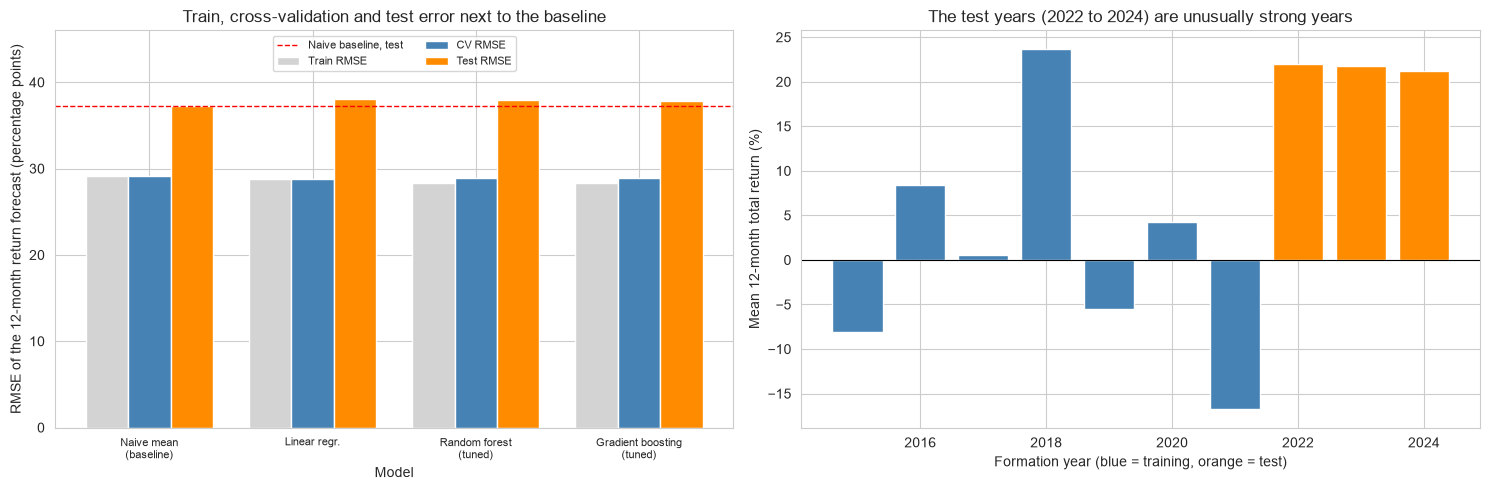

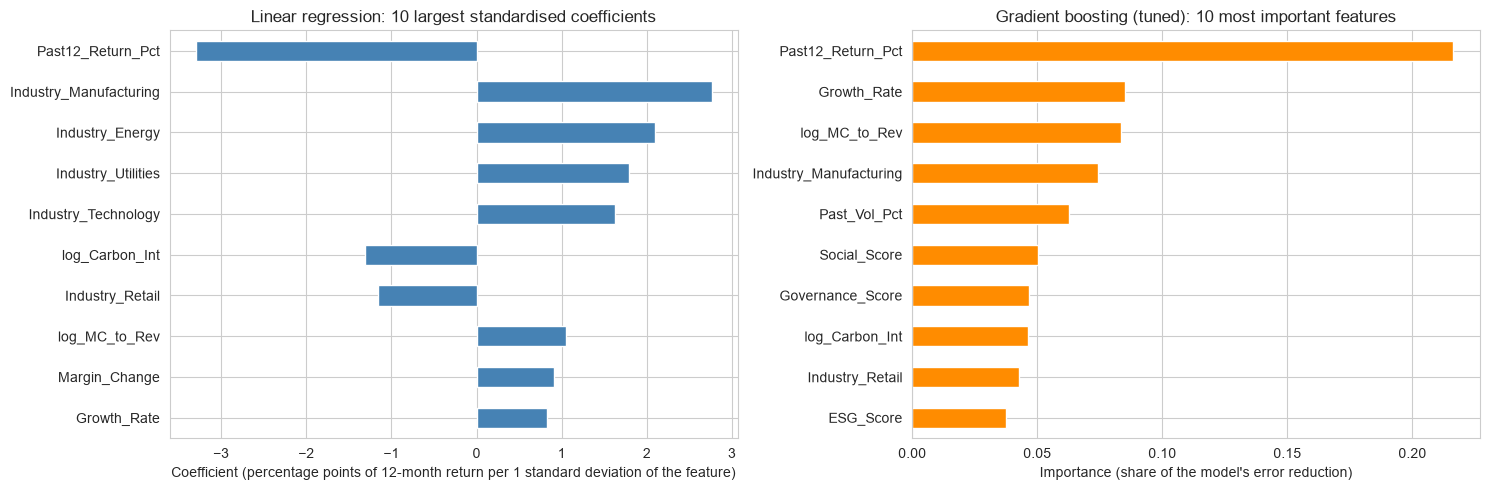

In [18]:
# ---- (b) Step 3: figures ----
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
labels = [i.replace(" (baseline)", "\n(baseline)").replace(" (tuned)", "\n(tuned)").replace("regression", "regr.") for i in comparison.index]
x = np.arange(len(comparison)); w = 0.26
for k, (col, colour) in enumerate([("Train RMSE", "lightgrey"), ("CV RMSE", "steelblue"), ("Test RMSE", "darkorange")]):
    axes[0].bar(x + (k - 1) * w, comparison[col], w, label=col, color=colour)
axes[0].axhline(comparison.loc["Naive mean (baseline)", "Test RMSE"], color="red", ls="--", lw=1, label="Naive baseline, test")
axes[0].set_xticks(x); axes[0].set_xticklabels(labels, fontsize=8)
axes[0].set_ylabel("RMSE of the 12-month return forecast (percentage points)"); axes[0].set_xlabel("Model")
axes[0].set_ylim(0, 46); axes[0].set_title("Train, cross-validation and test error next to the baseline")
axes[0].legend(fontsize=8, ncol=2, loc="upper center")

by_year = model_data_a.groupby("Formation_Year")[TARGET].mean()
axes[1].bar(by_year.index, by_year.values, color=["steelblue" if y <= 2021 else "darkorange" for y in by_year.index])
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_xlabel("Formation year (blue = training, orange = test)"); axes[1].set_ylabel("Mean 12-month total return (%)")
axes[1].set_title("The test years (2022 to 2024) are unusually strong years")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
lin = fitted["Linear regression"]
coef = pd.Series(lin.named_steps["linearregression"].coef_, index=feature_cols_a)
coef.reindex(coef.abs().sort_values(ascending=False).index).head(10)[::-1].plot(kind="barh", ax=axes[0], color="steelblue")
axes[0].set_xlabel("Coefficient (percentage points of 12-month return per 1 standard deviation of the feature)")
axes[0].set_title("Linear regression: 10 largest standardised coefficients")
imp = pd.Series(fitted[best_ens].feature_importances_, index=feature_cols_a).sort_values(ascending=False)
imp.head(10)[::-1].plot(kind="barh", ax=axes[1], color="darkorange")
axes[1].set_xlabel("Importance (share of the model's error reduction)"); axes[1].set_title(f"{best_ens}: 10 most important features")
plt.tight_layout(); plt.show()

In [19]:
# ---- (b) Step 4: the result in words and the numbers for results.json ----
lin_rmse = comparison.loc["Linear regression", "Test RMSE"]
base_rmse = comparison.loc["Naive mean (baseline)", "Test RMSE"]
ens_rmse = comparison.loc[best_ens, "Test RMSE"]
ens_kind = "random forest" if best_ens.startswith("Random") else "gradient boosting"
key = selected.replace(" (tuned)", "")
sel_text = f"{selected} {best_params[key]}" if key in best_params else selected
task_b = dict(target="twelve-month total holding return in percent (July to June after formation)",
              test_formation_years=[2022, 2023, 2024],
              baseline_rmse=float(base_rmse), linear_rmse=float(lin_rmse), ensemble_rmse=float(ens_rmse),
              ensemble_kind=ens_kind, selected_on_cv=sel_text, test_r2=float(comparison.loc[selected, "Test R2"]))
print(task_b)
pays = ens_rmse < min(lin_rmse, base_rmse)
vs_lin = "better" if ens_rmse < lin_rmse else "worse"
vs_base = "better" if ens_rmse < base_rmse else "worse"
print(f"\nTest RMSE (percentage points): naive baseline {base_rmse:.2f}, linear regression {lin_rmse:.2f}, best ensemble ({best_ens}) {ens_rmse:.2f}.")
print(f"The best ensemble is {abs(ens_rmse - lin_rmse):.2f} points {vs_lin} than linear regression and {abs(ens_rmse - base_rmse):.2f} points {vs_base} than the naive baseline, "
      f"so the extra complexity of the ensemble {'pays off' if pays else 'does not pay off'} out of sample.")

{'target': 'twelve-month total holding return in percent (July to June after formation)', 'test_formation_years': [2022, 2023, 2024], 'baseline_rmse': 37.19840887818676, 'linear_rmse': 38.10353177095792, 'ensemble_rmse': 37.8381469721778, 'ensemble_kind': 'gradient boosting', 'selected_on_cv': 'Linear regression', 'test_r2': -0.5191195394473065}

Test RMSE (percentage points): naive baseline 37.20, linear regression 38.10, best ensemble (Gradient boosting (tuned)) 37.84.
The best ensemble is 0.27 points better than linear regression and 0.64 points worse than the naive baseline, so the extra complexity of the ensemble does not pay off out of sample.


**Reading the result of task (b).** No model beats the naive baseline on the test years: test RMSE 37.20 for the baseline against 38.10 (linear regression), 37.90 (random forest) and 37.84 (gradient boosting), and test R2 of -0.45 against -0.50 to -0.52. The tuned ensembles are 0.2 to 0.3 points better than the linear model but 0.6 to 0.7 points worse than the baseline, so the extra complexity does not pay off out of sample. This is a legitimate result: returns are hard to forecast.

*Selection.* Cross-validation (grouped by company, inside the training years) puts the three models almost level: 28.84 (linear), 28.87 (gradient boosting) and 28.91 (random forest), a spread of 0.07 points against a fold-to-fold standard deviation of about 0.5. Following the rule fixed in advance (lowest CV RMSE) the selected model is **linear regression**, but this is effectively a tie, not a clear win.

*Why test error is so much higher than CV error (28.8 against 37 to 38).* The test years are unusually strong years: the mean 12-month return is 21.6% in 2022 to 2024 against 0.9% in the training years, so a forecast built on the training average is far too low. A naive forecast that already knew each test year's mean would have a test RMSE of 30.9. Cross-validation mixes years inside the training period, so it cannot see this shift.

*Ranking skill.* The rank correlation between forecast and outcome within each test year is -0.02 to -0.03 for all three models: no sign that any of them ranks firms usefully in the test years. For task (d), a ranking built on these forecasts should not be expected to beat the equal-weight benchmark.

# 6. Submission file

`results.json` is the machine-readable half of your submission. It carries the same headline numbers your memo reports, in a fixed format, so grading can check them against the notebook and the memo before a person reads either. The audit section stays a free list in your own words: task (a) is worth twenty points because you find the problems yourselves, and a schema with a named field for each planted problem would tell you what to look for. Everything else records a number you already computed for tasks (b) to (d), in the same units as the memo.

Fill in the template below with the values from your own run, keeping the same keys, then call `write_results` again as the last cell of your notebook, so the file you submit matches your final results.


In [20]:
import json

RESULTS_TEMPLATE = {
    "group": "",                    # e.g. "Group 7"
    "members": [],                  # full names of every group member
    "audit": [                      # one entry per problem you found and treated, in your own words
        {
            "issue": "",             # short description of what you found
            "file": "",               # which file it is in
            "detected_by": "",         # how you found it
            "treatment": "",           # what you did about it
            "affected_ids": [],        # Company_IDs it affects, if there is a natural list; may stay empty
            "affected_count": 0,       # how many rows or firms it affects
            "effect": "",               # which number it changed, and by how much
        },
    ],
    "task_b": {
        "target": "",                # what you forecast, e.g. "twelve-month holding return"
        "test_formation_years": [],  # formation years held out for the test set
        "baseline_rmse": 0.0,        # naive mean baseline, test RMSE
        "linear_rmse": 0.0,          # linear regression, test RMSE
        "ensemble_rmse": 0.0,        # your selected ensemble, test RMSE
        "ensemble_kind": "",         # "random forest" or "gradient boosting"
        "selected_on_cv": "",        # which model/setting cross-validation selected
        "test_r2": 0.0,              # selected model's test R2
    },
    "task_c": {
        "estimates": [               # point-in-time scores, one row per region x period
            {"region": "", "period": "", "coef": 0.0, "se": 0.0, "n": 0},
        ],
        "restated": [                # same cells, restated scores
            {"region": "", "period": "", "coef": 0.0, "se": 0.0, "n": 0},
        ],
        "conclusion": "",            # where an investor could have earned a premium, and where not
    },
    "task_d": {
        "rules": [                   # one row per rule: no floor, each floor, benchmark
            {"name": "", "ann_return_pct": 0.0, "ann_vol_pct": 0.0, "sharpe": 0.0, "turnover": 0.0},
        ],
        "bootstrap": {"statistic": "", "point": 0.0, "lo": 0.0, "hi": 0.0},  # what you bootstrapped, and the interval
        "universe": "",              # "full panel including firms that left" or "survivors only"
    },
}


def _check(data, template, path):
    # Walks RESULTS_TEMPLATE's shape and checks data against it: every key in the template must be
    # present in data, and every numeric leaf in the template must be a number (not a string) in data.
    if isinstance(template, dict):
        if not isinstance(data, dict):
            raise ValueError(f"results.json: '{path}' should be an object, got {type(data).__name__}")
        for key, sub_template in template.items():
            sub_path = f"{path}.{key}" if path else key
            if key not in data:
                raise ValueError(f"results.json: missing required key '{sub_path}'")
            _check(data[key], sub_template, sub_path)
    elif isinstance(template, list):
        if not isinstance(data, list):
            raise ValueError(f"results.json: '{path}' should be a list, got {type(data).__name__}")
        if template and data:
            item_template = template[0]
            for i, item in enumerate(data):
                _check(item, item_template, f"{path}[{i}]")
    elif isinstance(template, (int, float)) and not isinstance(template, bool):
        if isinstance(data, bool) or not isinstance(data, (int, float)):
            raise ValueError(f"results.json: '{path}' should be a number, got {type(data).__name__} ({data!r})")


def write_results(data, path="results.json"):
    # Validates data against the submission contract's schema, writes it, and prints what it wrote.
    # Raises ValueError naming the exact key that is missing or has the wrong type.
    _check(data, RESULTS_TEMPLATE, "")
    with open(path, "w") as f:
        json.dump(data, f, indent=2)
    print(f"wrote {path}")
    print(f"  group: {data['group'] or '(not set)'}, {len(data['members'])} member(s)")
    print(f"  audit: {len(data['audit'])} entr{'y' if len(data['audit']) == 1 else 'ies'}")
    print(f"  task_b: selected on CV = {data['task_b']['selected_on_cv'] or '(not set)'}, test R2 = {data['task_b']['test_r2']}")
    print(f"  task_c: {len(data['task_c']['estimates'])} point-in-time estimate(s), {len(data['task_c']['restated'])} restated")
    print(f"  task_d: {len(data['task_d']['rules'])} rule(s), universe = {data['task_d']['universe'] or '(not set)'}")


# Run once now, on the template as it ships, so you see a valid file before you change a single value.
# Fill in RESULTS_TEMPLATE (or build your own dict with the same keys) with your own numbers, then call
# write_results again as the last cell of your notebook.
write_results(RESULTS_TEMPLATE)


wrote results.json
  group: (not set), 0 member(s)
  audit: 1 entry
  task_b: selected on CV = (not set), test R2 = 0.0
  task_c: 1 point-in-time estimate(s), 1 restated
  task_d: 1 rule(s), universe = (not set)
